# SAM 3: Text-Prompted Vehicle Segmentation & Tracking in Video

This notebook segments and **tracks every vehicle** in a video using a **text prompt** (e.g. `"car"`, `"vehicle"`) with **SAM 3**
(Promptable Concept Segmentation) through the Hugging Face Transformers implementation (`Sam3VideoModel`).

**Runs anywhere:** NVIDIA GPU (`cuda`), Apple Silicon (`mps`) or plain `cpu`, on Windows, Linux, macOS and Google Colab.
The device is detected automatically and the video length / resolution defaults are chosen from the available memory.

**Outputs** (in `./sam3_output/`): an overlay video (`tracked_output.mp4`), a table of all tracks (`tracks.csv`), and the raw frames + one binary mask per object (`frames/`, `masks/`), which are the input of the separate SAM 3D notebook.

---

## 1. Create a virtual environment (Python 3.10+)

Choose **one** option in your terminal.

**Conda / Mamba**
```bash
conda create -n sam3_env python=3.10 -y
conda activate sam3_env
```

**venv**
```bash
# macOS / Linux
python3 -m venv sam3_env
source sam3_env/bin/activate

# Windows (PowerShell)
python -m venv sam3_env
.\sam3_env\Scripts\Activate.ps1
```

**uv**
```bash
uv venv sam3_env --python 3.10
source sam3_env/bin/activate   # Windows: .\sam3_env\Scripts\activate
```

---

## 2. Install dependencies

**PyTorch** (pick ONE; for other CUDA versions use the selector at https://pytorch.org/get-started/locally/):
```bash
# NVIDIA GPU on Windows / Linux (cu128 also supports RTX 50xx; use cu126 for older drivers)
pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128

# Apple Silicon, Intel Mac, or CPU-only machines
pip install torch torchvision
```

**Everything else** (a recent Transformers release is required for SAM 3):
```bash
pip install -U transformers accelerate "huggingface_hub[cli]" opencv-python pillow matplotlib psutil tqdm ipykernel
```

Optional, for cleaner masks (NMS, hole filling, sprinkle removal; may be unavailable on some platforms):
```bash
pip install kernels
```

> The `sam3` GitHub package is **not** needed.

**Google Colab / Kaggle:** select a GPU runtime, run `!pip install -U transformers accelerate opencv-python psutil` in a cell,
and store your Hugging Face token as a secret named `HF_TOKEN`.

---

## 3. Connect the kernel in VS Code

1. Click **Select Kernel** (top right).
2. Choose **Python Environments...** and select `sam3_env`.
3. If it is not listed: **Enter interpreter path...** and point to `sam3_env/bin/python` (macOS/Linux) or `sam3_env\Scripts\python.exe` (Windows).

---

## 4. Hugging Face access

The weights (`facebook/sam3`) are in a gated repository:

1. Request access on the [facebook/sam3 page](https://huggingface.co/facebook/sam3).
2. Log in from a terminal with `hf auth login`, **or** set the `HF_TOKEN` environment variable, **or** just run Cell 1: it will ask for a token if none is found.

---

## 5. Tips

* Run the cells **in order, once**. If something fails, use **Restart kernel** before retrying.
* If you run out of memory, set `PRESET = "low"` in Cell 2 (or lower the values in `OVERRIDES`).
* Prompts must be **short English noun phrases**: `"car"`, `"vehicle"`, `"truck"`, `"bus"`, `"white van"`.

# Video

Put a video named `input_video.mp4` next to this notebook (or change `VIDEO_PATH` in Cell 2).
A **static camera** with moving vehicles works best.

Open-access traffic datasets (links taken from the original notebook, not re-verified):

* **Zenodo**, multi-perspective traffic recording (University of Murcia): https://zenodo.org/records/13061961
* **Mendeley Data**, vehicle traffic recordings: https://data.mendeley.com/datasets/8k86t83wy5/1
* **Aalborg University Multi-View Traffic Intersection Dataset (MTID)**: search for it on Kaggle (https://www.kaggle.com/).

# Cell 1: Imports, hardware detection, Hugging Face login

In [1]:
import os

# Must be set BEFORE importing torch: unsupported MPS ops fall back to CPU instead of crashing
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import gc
import csv
import json
import colorsys
import platform
from pathlib import Path

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from huggingface_hub import login, get_token


def total_memory_gb(device):
    """GPU memory for CUDA, system RAM otherwise (None if unknown)."""
    if device == "cuda":
        return torch.cuda.get_device_properties(0).total_memory / 1e9
    try:
        import psutil
        return psutil.virtual_memory().total / 1e9
    except Exception:
        pass
    try:
        return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
    except Exception:
        return None


def detect_hardware():
    print(f"OS: {platform.system()} ({platform.machine()}) | Python {platform.python_version()} | PyTorch {torch.__version__}")
    if torch.cuda.is_available():
        device = "cuda"
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        print(f"NVIDIA GPU: {torch.cuda.get_device_name(0)}")
    elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        device, dtype = "mps", torch.float16
        print("Apple Silicon (MPS)")
    else:
        device, dtype = "cpu", torch.float32
        print("CPU only: inference will be slow")
    mem = total_memory_gb(device)
    print(f"Memory: {mem:.1f} GB ({'VRAM' if device == 'cuda' else 'system RAM'})" if mem else "Memory: unknown")
    return device, dtype, mem


DEVICE, DTYPE, MEM_GB = detect_hardware()

# Rough usable-memory estimate -> suggested preset (heuristic, not a guarantee)
if DEVICE == "cpu":
    AUTO_PRESET = "low"
else:
    usable = (MEM_GB or 0) * (0.6 if DEVICE == "mps" else 1.0)   # MPS can only use part of the unified memory
    AUTO_PRESET = "high" if usable >= 20 else "medium" if usable >= 10 else "low"
print(f"Device: {DEVICE} | dtype: {DTYPE} | suggested preset: {AUTO_PRESET}")

# Hugging Face authentication (needed once for the gated facebook/sam3 repo)
if os.environ.get("HF_TOKEN") or get_token():
    print("Hugging Face token found.")
else:
    print("No Hugging Face token found: please log in below.")
    login()

OS: Darwin (arm64) | Python 3.10.22 | PyTorch 2.14.1
Apple Silicon (MPS)
Memory: 8.6 GB (system RAM)
Device: mps | dtype: torch.float16 | suggested preset: low
Hugging Face token found.


# Cell 2: Settings (the only cell you normally need to edit)

In [2]:
# ---------------- What to track ----------------
VIDEO_PATH = "input_video.mp4"
PROMPTS = ["car"]            # short English noun phrases. Try ["vehicle"] or ["car", "truck", "bus"]
                             # (overlapping prompts such as "car" + "vehicle" may produce duplicate tracks)

# ---------------- Which part of the video ----------------
START_SECONDS = 0            # start of the analysed segment
FPS_TARGET = 10              # approximate frames per second to analyse

# ---------------- Performance ----------------
PRESET = "auto"              # "auto", "low", "medium" or "high"
OVERRIDES = {}               # e.g. {"MAX_FRAMES": 200, "MAX_WIDTH": 800, "IMAGE_SIZE": None}
                             # IMAGE_SIZE=None -> native 1008 px (most accurate, most memory)

DETECTION_THRESHOLD = None   # None -> model default (0.5). Lower = more detections, more false positives.
OUTPUT_DIR = "./sam3_output"
SAVE_EVERY = 1               # save the raw frame + one mask PNG per object every N frames (input for the SAM 3D notebook)
# ------------------------------------------------

PRESETS = {
    "low":    {"MAX_FRAMES": 60,  "MAX_WIDTH": 640,  "IMAGE_SIZE": 560},
    "medium": {"MAX_FRAMES": 150, "MAX_WIDTH": 960,  "IMAGE_SIZE": None},
    "high":   {"MAX_FRAMES": 300, "MAX_WIDTH": 1280, "IMAGE_SIZE": None},
}

preset_name = AUTO_PRESET if PRESET == "auto" else PRESET
assert preset_name in PRESETS, f"Unknown PRESET: {PRESET}"
assert isinstance(PROMPTS, list) and PROMPTS and all(isinstance(p, str) for p in PROMPTS), "PROMPTS must be a non-empty list of strings"

settings = {**PRESETS[preset_name], **OVERRIDES}
MAX_FRAMES, MAX_WIDTH, IMAGE_SIZE = settings["MAX_FRAMES"], settings["MAX_WIDTH"], settings["IMAGE_SIZE"]

OUT_DIR = Path(OUTPUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Preset: {preset_name} -> MAX_FRAMES={MAX_FRAMES}, MAX_WIDTH={MAX_WIDTH}, IMAGE_SIZE={IMAGE_SIZE or 'native (1008)'}")
print(f"Prompts: {PROMPTS}")

Preset: low -> MAX_FRAMES=60, MAX_WIDTH=640, IMAGE_SIZE=560
Prompts: ['car']


# Cell 3: Load the video frames (kept in memory, no temporary files)

Native FPS: 25.00 | 1 frame every 2 (~12.50 fps) | start at frame 0
Loaded 60 frames (640x360), covering ~4.8 s of video


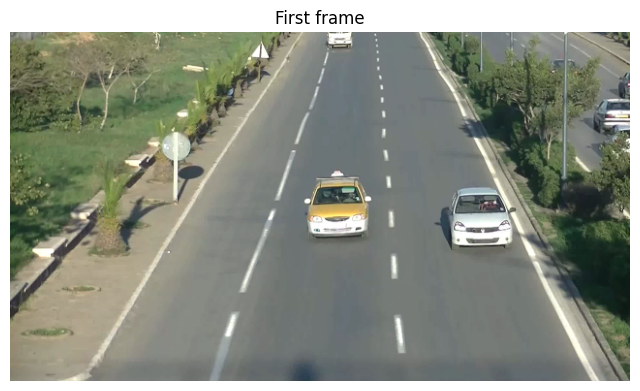

In [3]:
def find_video(path):
    p = Path(path)
    if p.exists():
        return p
    exts = {".mp4", ".avi", ".mov", ".mkv", ".webm"}
    nearby = sorted(f.name for f in Path(".").iterdir() if f.suffix.lower() in exts)
    raise FileNotFoundError(f"Video not found: {path}. Video files in this folder: {nearby or 'none'}")


def load_frames(video_path, start_s, target_fps, max_frames, max_width):
    cap = cv2.VideoCapture(str(video_path))
    native_fps = cap.get(cv2.CAP_PROP_FPS)
    if not native_fps or native_fps <= 0:
        raise ValueError("Could not read the video FPS (unsupported or corrupted file?).")

    interval = max(1, int(round(native_fps / target_fps)))
    effective_fps = native_fps / interval
    start_frame = int(start_s * native_fps)
    print(f"Native FPS: {native_fps:.2f} | 1 frame every {interval} (~{effective_fps:.2f} fps) | start at frame {start_frame}")

    for _ in range(start_frame):          # skip to the start without decoding
        if not cap.grab():
            break

    frames, read_count = [], 0
    while len(frames) < max_frames:
        ok, bgr = cap.read()
        if not ok:
            break
        if read_count % interval == 0:
            h, w = bgr.shape[:2]
            if w > max_width:
                bgr = cv2.resize(bgr, (max_width, int(round(h * max_width / w))), interpolation=cv2.INTER_AREA)
            frames.append(Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)))
        read_count += 1
    cap.release()
    if not frames:
        raise RuntimeError("No frames were read. Check VIDEO_PATH and START_SECONDS.")
    info = {"native_fps": native_fps, "interval": interval, "start_frame": start_frame}
    return frames, effective_fps, info


VIDEO_FILE = find_video(VIDEO_PATH)
frames, OUTPUT_FPS, FRAME_INFO = load_frames(VIDEO_FILE, START_SECONDS, FPS_TARGET, MAX_FRAMES, MAX_WIDTH)
W, H = frames[0].size
print(f"Loaded {len(frames)} frames ({W}x{H}), covering ~{len(frames) / OUTPUT_FPS:.1f} s of video")

plt.figure(figsize=(8, 5))
plt.imshow(frames[0])
plt.title("First frame")
plt.axis("off")
plt.show()

# Cell 4: Load SAM 3 (run once)

In [4]:
from transformers import Sam3VideoConfig, Sam3VideoModel, Sam3VideoProcessor

# Free anything left over from a previous attempt
for _name in ("model", "session"):
    if _name in globals():
        del globals()[_name]
gc.collect()
if DEVICE == "mps":
    torch.mps.empty_cache()
elif DEVICE == "cuda":
    torch.cuda.empty_cache()

MODEL_ID = "facebook/sam3"

config = Sam3VideoConfig.from_pretrained(MODEL_ID)
if IMAGE_SIZE:                       # lower resolution = less memory, but lower accuracy
    config.image_size = IMAGE_SIZE
if DETECTION_THRESHOLD is not None:
    config.score_threshold_detection = DETECTION_THRESHOLD

print("Loading model...")
model = Sam3VideoModel.from_pretrained(MODEL_ID, config=config).to(DEVICE, dtype=DTYPE).eval()
if IMAGE_SIZE:
    processor = Sam3VideoProcessor.from_pretrained(MODEL_ID, size={"height": IMAGE_SIZE, "width": IMAGE_SIZE})
else:
    processor = Sam3VideoProcessor.from_pretrained(MODEL_ID)
print("Model ready.")

/opt/homebrew/anaconda3/envs/sam3_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/homebrew/anaconda3/envs/sam3_env/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[transformers] `memory_attention_rope_theta` is deprecated and will be removed in v5.0. Use `rope_parameters['rope_theta']` instead.


Loading model...


Loading weights: 100%|██████████| 1797/1797 [00:00<00:00, 6146.85it/s]


Model ready.


# Cell 5: Track all objects matching the text prompt(s)

In [5]:
def color_for(obj_id):
    """Stable, well-separated RGB color per object id."""
    r, g, b = colorsys.hsv_to_rgb((obj_id * 0.61803398875) % 1.0, 0.75, 1.0)
    return int(r * 255), int(g * 255), int(b * 255)


def get_masks(res):
    """Boolean masks, shape (num_objects, H, W)."""
    masks = res["masks"].float().cpu().numpy() > 0.5
    return masks.reshape(masks.shape[0], *masks.shape[-2:])


def render(frame_pil, res, id_to_prompt, masks):
    """Draw masks, boxes and labels for one frame. Returns an RGB uint8 image."""
    img = np.array(frame_pil)
    ids = res["object_ids"].tolist()
    if not ids:
        return img
    scores = res["scores"].tolist()
    boxes = res["boxes"].float().cpu().numpy()

    overlay = img.copy()
    for k, oid in enumerate(ids):
        overlay[masks[k]] = color_for(oid)
    img = cv2.addWeighted(overlay, 0.45, img, 0.55, 0)

    for k, oid in enumerate(ids):
        x1, y1, x2, y2 = [int(v) for v in boxes[k]]
        color = color_for(oid)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        label = f"{id_to_prompt.get(oid, '?')} #{oid} {scores[k]:.2f}"
        cv2.putText(img, label, (x1, max(12, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(img, label, (x1, max(12, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1, cv2.LINE_AA)
    return img


# --- Start a session and add the text prompt(s) ---
session = processor.init_video_session(
    video=frames,
    inference_device=DEVICE,
    processing_device="cpu",
    video_storage_device="cpu",
    dtype=DTYPE,
)
session = processor.add_text_prompt(inference_session=session, text=PROMPTS)

# --- Propagate through the video, rendering on the fly (low memory) ---
(OUT_DIR / "frames").mkdir(exist_ok=True)
(OUT_DIR / "masks").mkdir(exist_ok=True)
video_path_out = OUT_DIR / "tracked_output.mp4"
writer = cv2.VideoWriter(str(video_path_out), cv2.VideoWriter_fourcc(*"mp4v"), OUTPUT_FPS, (W, H))

n = len(frames)
preview_idx = sorted({0, n // 2, n - 1})
previews = {}                    # frame_idx -> rendered RGB image (only a few are kept)
rows = []                        # one row per (frame, object)
objects_per_prompt = {p: set() for p in PROMPTS}

try:
    with torch.inference_mode():
        for model_outputs in model.propagate_in_video_iterator(inference_session=session, show_progress_bar=True):
            idx = model_outputs.frame_idx
            res = processor.postprocess_outputs(session, model_outputs)

            id_to_prompt = {oid: p for p, oids in res["prompt_to_obj_ids"].items() for oid in oids}
            masks_np = get_masks(res)

            save_this = (idx % SAVE_EVERY == 0)
            frame_file = ""
            if save_this:                                   # raw frame, lossless
                frame_file = f"frames/frame_{idx:05d}.png"
                frames[idx].save(OUT_DIR / frame_file)

            for k, oid in enumerate(res["object_ids"].tolist()):
                x1, y1, x2, y2 = res["boxes"][k].float().tolist()
                prompt = id_to_prompt.get(oid, "?")
                objects_per_prompt.setdefault(prompt, set()).add(oid)
                mask_file = ""
                if save_this:                               # one binary mask PNG per object
                    mask_file = f"masks/frame_{idx:05d}_obj_{oid:03d}.png"
                    # PIL instead of cv2.imwrite: works with non-ASCII paths on Windows
                    Image.fromarray(masks_np[k].astype(np.uint8) * 255).save(OUT_DIR / mask_file)
                rows.append([idx, round(START_SECONDS + idx / OUTPUT_FPS, 3), oid, prompt,
                             round(float(res["scores"][k]), 4), round(x1, 1), round(y1, 1), round(x2, 1), round(y2, 1),
                             frame_file, mask_file])

            img = render(frames[idx], res, id_to_prompt, masks_np)
            writer.write(cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
            if idx in preview_idx:
                previews[idx] = img
finally:
    writer.release()

# --- Save the track table ---
csv_path = OUT_DIR / "tracks.csv"
with open(csv_path, "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["frame", "time_s", "object_id", "prompt", "score", "x1", "y1", "x2", "y2", "frame_file", "mask_file"])
    wr.writerows(rows)

run_info = {
    "video_path": str(Path(VIDEO_FILE).resolve()), "prompts": PROMPTS, "start_seconds": START_SECONDS,
    "processed_size": [W, H], "output_fps": OUTPUT_FPS, "save_every": SAVE_EVERY, **FRAME_INFO,
}
with open(OUT_DIR / "run_info.json", "w") as f:
    json.dump(run_info, f, indent=2)

print(f"\nSaved: {video_path_out}")
print(f"Saved: {csv_path} ({len(rows)} rows), frames/ and masks/ (inputs for the SAM 3D notebook)")
for p, ids in objects_per_prompt.items():
    print(f"  '{p}': {len(ids)} unique objects tracked")
if not rows:
    print("No objects found. Try a different prompt, a lower DETECTION_THRESHOLD, or a higher-resolution preset.")

propagate in video: 100%|██████████| 60/60 [06:14<00:00,  6.24s/it]



Saved: sam3_output/tracked_output.mp4
Saved: sam3_output/tracks.csv (484 rows), frames/ and masks/ (inputs for the SAM 3D notebook)
  'car': 13 unique objects tracked


# Cell 6: Preview results

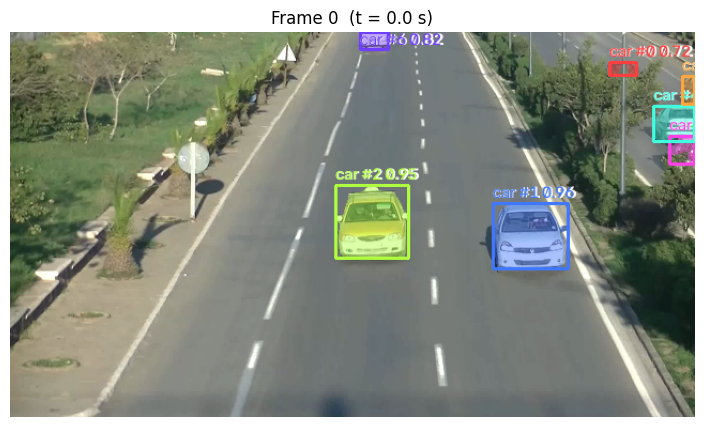

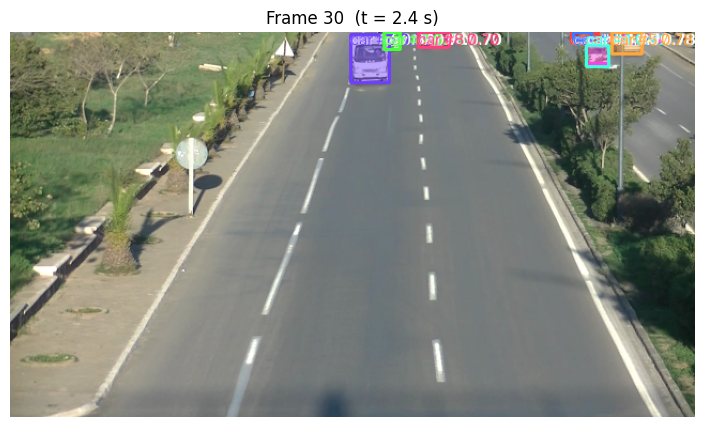

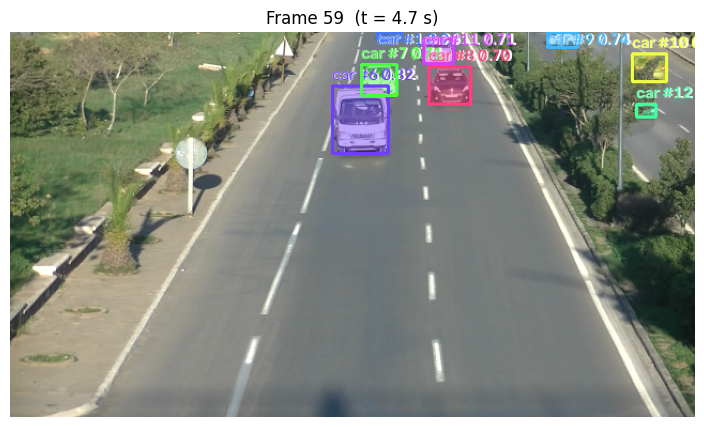

In [6]:
for idx in sorted(previews):
    plt.figure(figsize=(9, 5))
    plt.imshow(previews[idx])
    plt.title(f"Frame {idx}  (t = {START_SECONDS + idx / OUTPUT_FPS:.1f} s)")
    plt.axis("off")
    plt.show()

# Cell 7 (optional): Free memory

In [7]:
for _name in ("model", "session", "processor"):
    if _name in globals():
        del globals()[_name]
gc.collect()
if DEVICE == "mps":
    torch.mps.empty_cache()
elif DEVICE == "cuda":
    torch.cuda.empty_cache()
print("Memory released.")

Memory released.
